In [1]:
#Import libraries
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import os

In [2]:
# Reading dataset 
df = pd.read_csv('./CrisisMMD_v2.0/annotations/california_wildfires_final_data.tsv', sep='\t')

df.head(1)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path
0,917791044158185473,917791044158185473_0,informative,1.0,informative,0.6766,other_relevant_information,1.0,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...


In [3]:
# merged all tsv file into dataframe with extra label "diaster_label" for better preprocessing 

base_path = './CrisisMMD_v2.0'
annotations_dir = os.path.join(base_path, 'annotations')

all_dataframes = []

for filename in os.listdir(annotations_dir):
    if filename.endswith('.tsv') and not filename.startswith('._'):
        file_path = os.path.join(annotations_dir, filename)
        
        temp_df = pd.read_csv(file_path, sep='\t')
        
        disaster_label = filename.replace('_final_data.tsv', '')
        temp_df['disaster_type'] = disaster_label
        
        all_dataframes.append(temp_df)

master_df = pd.concat(all_dataframes, ignore_index=True)

print(f"Total rows merged: {len(master_df)}")
print(master_df['disaster_type'].value_counts())

Total rows merged: 18082
disaster_type
hurricane_maria         4556
hurricane_irma          4504
hurricane_harvey        4434
california_wildfires    1589
mexico_earthquake       1380
srilanka_floods         1022
iraq_iran_earthquake     597
Name: count, dtype: int64


In [4]:
master_df.head(1)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path,disaster_type
0,917791044158185473,917791044158185473_0,informative,1.0,informative,0.6766,other_relevant_information,1.0,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires


Tweet Index: 1500 | Event: california_wildfires
TEXT: Wildfires prompt congressional push for better disaster prevention in California https://t.co/Dw7lQm6OBb https://t.co/vl8hHJRuF5
LABEL (Text): other_relevant_information
LABEL (Image): rescue_volunteering_or_donation_effort





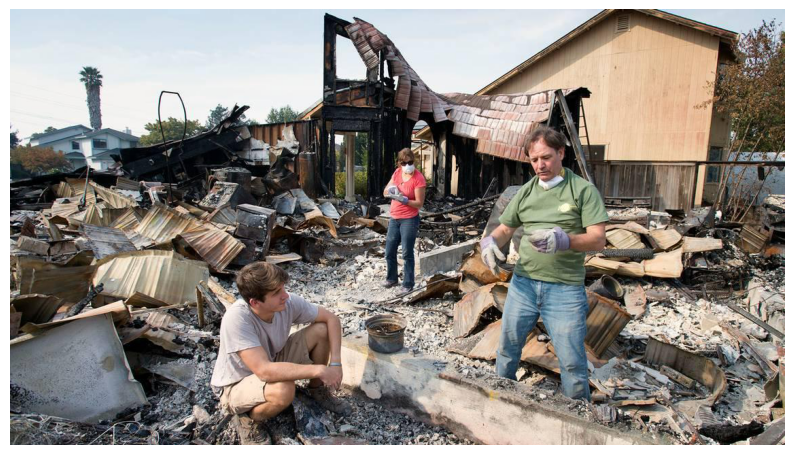

In [7]:
#Display text and tweet image

def display_tweet(df, index):

    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)
    

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 1500)